# Peramalan Rata-rata Konsentrasi PM2.5 Harian di Indonesia Menggunakan Long Short-Term Memory (LSTM)

**Tujuan:** membangun model LSTM yang memprediksi rata-rata konsentrasi PM2.5 harian nasional untuk **esok hari** berdasarkan data historis 31 kota, sebagai dasar sistem peringatan dini kualitas udara tingkat nasional.


**Alur:** Load data → Eksplorasi → Agregasi nasional → Feature engineering → Split kronologis → Normalisasi → Sliding window → Bangun & latih LSTM → Evaluasi (vs baseline) → Simpan model → Prediksi besok.

## 1. Import Library & Konfigurasi

In [17]:
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Path (notebook berada di folder notebook/)
DATA_PATH = '../data/idn_air_quality_daily.csv'
MODEL_DIR = '../model'
os.makedirs(MODEL_DIR, exist_ok=True)

# Hyperparameter
TIMESTEPS = 30        # jumlah hari historis sebagai input
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15      # sisanya (15%) untuk test
EPOCHS = 100
BATCH_SIZE = 32
TARGET = 'pm25_nasional'
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 2. Load Data

In [18]:
df = pd.read_csv(DATA_PATH, parse_dates=['date'])
print(df.shape)
df.head()

(48019, 11)


,city,province,island,date,pm2_5_mean,pm2_5_max,pm10_mean,us_aqi_mean,us_aqi_max,hours,exceeds_who_pm25
0,Ambon,Maluku,Maluku,2022-08-04,7.120000,9.8,12.473333,NaN,NaN,15,False
1,Ambon,Maluku,Maluku,2022-08-05,6.341667,8.4,10.900000,32.333333,35.0,24,False
2,Ambon,Maluku,Maluku,2022-08-06,5.520833,8.6,9.591667,36.083333,38.0,24,False
3,Ambon,Maluku,Maluku,2022-08-07,3.420833,5.3,5.737500,23.583333,31.0,24,False
4,Ambon,Maluku,Maluku,2022-08-08,4.362500,5.6,7.429167,21.083333,24.0,24,False


In [19]:
print('Rentang tanggal :', df['date'].min().date(), 's/d', df['date'].max().date())
print('Jumlah kota     :', df['city'].nunique())
print('Jumlah hari     :', df['date'].nunique())
print('\nMissing value per kolom:')
print(df.isna().sum())

Rentang tanggal : 2022-08-04 s/d 2026-10-30
Jumlah kota     : 31
Jumlah hari     : 1549

Missing value per kolom:
city                 0
province             0
island               0
date                 0
pm2_5_mean           0
pm2_5_max            0
pm10_mean            0
us_aqi_mean         31
us_aqi_max          31
hours                0
exceeds_who_pm25     0
dtype: int64


## 3. Agregasi Tingkat Nasional
Data dirata-ratakan lintas 31 kota per hari sehingga menjadi satu deret waktu nasional. Fitur yang dipakai:

| Fitur | Keterangan |
|---|---|
| `pm25_nasional` | rata-rata `pm2_5_mean` seluruh kota (**target**) |
| `pm25_max` | rata-rata `pm2_5_max` seluruh kota |
| `pm10` | rata-rata `pm10_mean` seluruh kota |
| `aqi` | rata-rata `us_aqi_mean` seluruh kota |
| `pct_melebihi_who` | persentase kota yang melebihi ambang WHO PM2.5 |
| `doy_sin`, `doy_cos` | encoding musiman (hari dalam tahun) |

**Catatan penting:** konsentrasi PM2.5 bersifat miring ke kanan dan punya lonjakan ekstrem saat episode kabut asap. Karena itu fitur PM/AQI ditransformasi `log1p`, dan model **memprediksi perubahan log PM2.5 terhadap hari terakhir** (bukan nilai absolut). Dengan cara ini model tetap bisa meramalkan nilai di luar rentang data latih, yang tidak bisa dilakukan jika target dinormalisasi dengan MinMaxScaler.

In [20]:
daily = df.groupby('date').agg(
    pm25_nasional=('pm2_5_mean', 'mean'),
    pm25_max=('pm2_5_max', 'mean'),
    pm10=('pm10_mean', 'mean'),
    aqi=('us_aqi_mean', 'mean'),
    pct_melebihi_who=('exceeds_who_pm25', 'mean'),
).sort_index()

# Pastikan deret waktu harian kontinu, isi celah (jika ada) secara interpolasi
daily = daily.asfreq('D')
print('Tanggal hilang:', daily['pm25_nasional'].isna().sum())
daily = daily.interpolate(method='linear').ffill().bfill()
daily['pct_melebihi_who'] *= 100

RAW_COLS = ['pm25_nasional', 'pm25_max', 'pm10', 'aqi', 'pct_melebihi_who']
FEATURES = RAW_COLS + ['doy_sin', 'doy_cos']
daily = daily[RAW_COLS]          # data harian nasional (nilai asli, µg/m³)

def buat_fitur(raw):
    """Data harian nasional (RAW_COLS) -> fitur model: log-transform + encoding musiman.
    Fungsi yang sama harus dipakai saat inferensi di web."""
    f = raw.copy()
    for c in ['pm25_nasional', 'pm25_max', 'pm10', 'aqi']:
        f[c] = np.log1p(f[c])
    doy = f.index.dayofyear
    f['doy_sin'] = np.sin(2 * np.pi * doy / 365.25)
    f['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
    return f[FEATURES]

daily.describe().T

Tanggal hilang: 0


,count,mean,std,min,25%,50%,75%,max
pm25_nasional,1549.0,21.201577,9.469150,0.723925,17.024866,19.202285,22.239919,96.335753
pm25_max,1549.0,36.928845,20.853798,0.909677,27.148387,32.461290,38.861290,198.306452
pm10,1549.0,26.595430,9.466243,1.037097,21.890591,24.764113,28.065860,99.951613
aqi,1549.0,70.595255,13.863204,14.336022,63.745968,68.200269,73.416667,167.047043
pct_melebihi_who,1549.0,44.061726,13.196331,0.000000,35.483871,41.935484,51.612903,100.000000


## 4. Eksplorasi Data

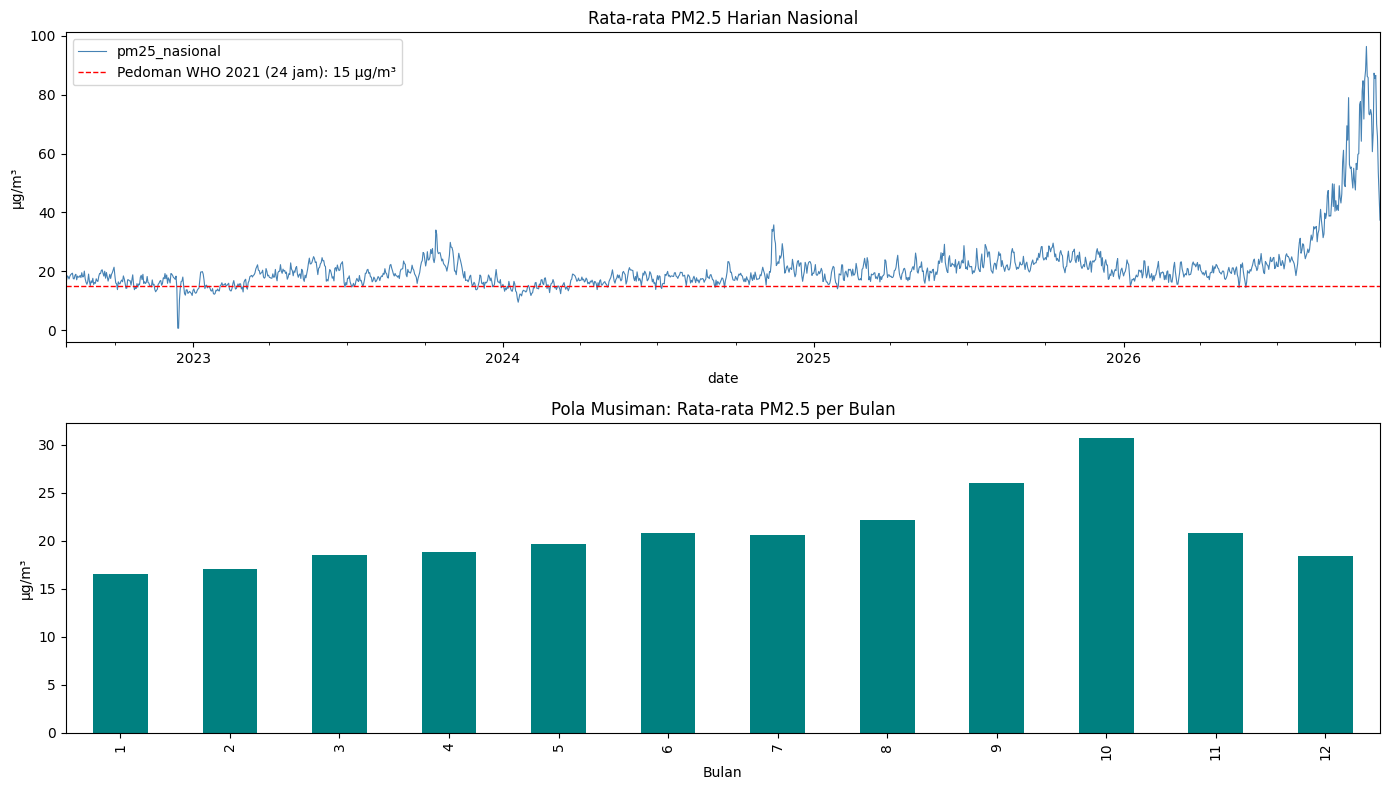

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
daily['pm25_nasional'].plot(ax=axes[0], color='steelblue', lw=0.8)
axes[0].axhline(15, color='red', ls='--', lw=1, label='Pedoman WHO 2021 (24 jam): 15 µg/m³')
axes[0].set_title('Rata-rata PM2.5 Harian Nasional'); axes[0].set_ylabel('µg/m³'); axes[0].legend()

monthly = daily['pm25_nasional'].groupby(daily.index.month).mean()
monthly.plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Pola Musiman: Rata-rata PM2.5 per Bulan'); axes[1].set_xlabel('Bulan'); axes[1].set_ylabel('µg/m³')
plt.tight_layout(); plt.show()

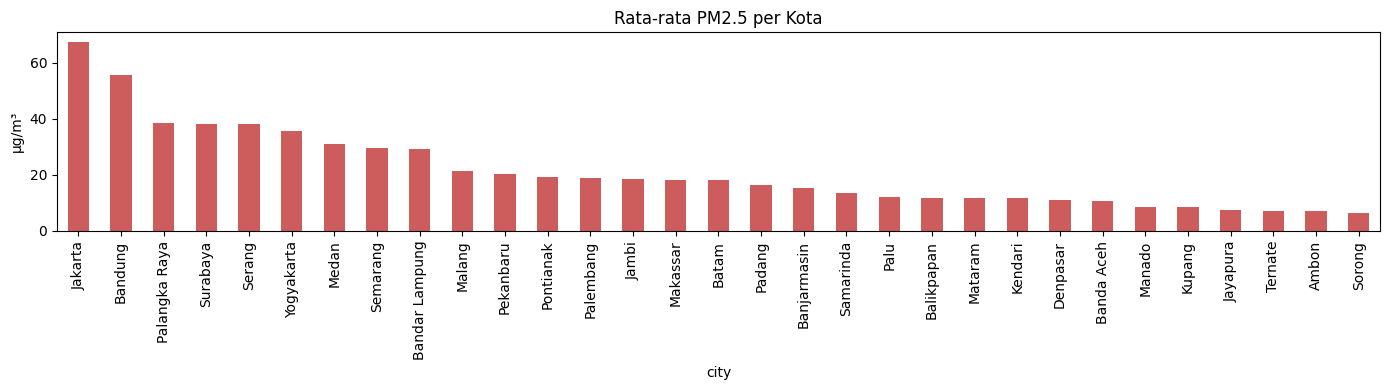

In [22]:
top = df.groupby('city')['pm2_5_mean'].mean().sort_values(ascending=False)
top.plot(kind='bar', figsize=(14, 4), color='indianred')
plt.title('Rata-rata PM2.5 per Kota'); plt.ylabel('µg/m³'); plt.tight_layout(); plt.show()

## 5. Split Data Kronologis & Normalisasi
Pada data time series, split **tidak boleh diacak**. Data dibagi berurutan: train → validation → test. `StandardScaler` hanya di-*fit* pada data train agar tidak terjadi *data leakage*.

In [23]:
n = len(daily)
train_end = int(n * TRAIN_RATIO)
val_end = int(n * (TRAIN_RATIO + VAL_RATIO))
print(f'Train: {train_end} hari | Val: {val_end-train_end} hari | Test: {n-val_end} hari')

feat = buat_fitur(daily)
scaler = StandardScaler().fit(feat.iloc[:train_end])   # fit hanya pada train
scaled = scaler.transform(feat)

# Cek pergeseran distribusi antar-periode (penting untuk interpretasi hasil)
for nama, seg in [('train', daily.iloc[:train_end]), ('val', daily.iloc[train_end:val_end]), ('test', daily.iloc[val_end:])]:
    print(f"{nama:5s} {seg.index.min().date()} s/d {seg.index.max().date()} | mean PM2.5 {seg[TARGET].mean():5.1f} | max {seg[TARGET].max():5.1f}")

Train: 1084 hari | Val: 232 hari | Test: 233 hari
train 2022-08-04 s/d 2025-07-22 | mean PM2.5  18.5 | max  35.8
val   2025-07-23 s/d 2026-03-11 | mean PM2.5  22.1 | max  29.6
test  2026-03-12 s/d 2026-10-30 | mean PM2.5  33.1 | max  96.3


## 6. Sliding Window
Input: data `TIMESTEPS` hari terakhir (semua fitur). Output: perubahan log PM2.5 nasional dari hari ini ke **hari berikutnya**, yang kemudian dikonversi kembali menjadi nilai PM2.5 (µg/m³).

In [24]:
log_pm = np.log1p(daily[TARGET].values)

X, y_delta, pos = [], [], []
for i in range(TIMESTEPS, len(scaled)):
    X.append(scaled[i - TIMESTEPS:i, :])          # TIMESTEPS hari sebelum hari i
    y_delta.append(log_pm[i] - log_pm[i - 1])     # perubahan log PM2.5 hari i vs hari i-1
    pos.append(i)
X, y_delta, pos = np.array(X), np.array(y_delta), np.array(pos)

# Split berdasarkan posisi tanggal target
idx_tr = pos < train_end
idx_va = (pos >= train_end) & (pos < val_end)
idx_te = pos >= val_end

# Normalisasi target (selisih log), fit hanya pada train
target_scaler = StandardScaler().fit(y_delta[idx_tr].reshape(-1, 1))
y_s = target_scaler.transform(y_delta.reshape(-1, 1)).ravel()

X_train, y_train = X[idx_tr], y_s[idx_tr]
X_val,   y_val   = X[idx_va], y_s[idx_va]
X_test,  y_test  = X[idx_te], y_s[idx_te]
dates_val  = daily.index[pos[idx_va]]
dates_test = daily.index[pos[idx_te]]

print('X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)

X_train (1054, 30, 7) | X_val (232, 30, 7) | X_test (233, 30, 7)


## 7. Bangun Model LSTM

In [25]:
model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Training
*Early stopping* menghentikan training saat val loss tidak membaik, dan model terbaik otomatis disimpan ke folder `model/`.

In [30]:
BEST_MODEL_PATH = os.path.join(MODEL_DIR, 'lstm_pm25_best.keras')

callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5),
    ModelCheckpoint(BEST_MODEL_PATH, monitor='val_loss', save_best_only=True),
]

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=callbacks, verbose=1,
    shuffle=False,
)

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.7749 - val_loss: 0.4090 - learning_rate: 2.5000e-04
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.7664 - val_loss: 0.4105 - learning_rate: 2.5000e-04
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.8156 - val_loss: 0.4103 - learning_rate: 2.5000e-04
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.7708 - val_loss: 0.4115 - learning_rate: 2.5000e-04
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.7527 - val_loss: 0.4111 - learning_rate: 2.5000e-04
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.7559 - val_loss: 0.4115 - learning_rate: 2.5000e-04
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.7628 - val_loss: 0.4128 - learning_rate: 2.5000e-04
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.7558 - val_loss: 0.4120 - learning_rate: 1.2500e-04
Epoch 9/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.7641 - val_loss: 0.4130 - 

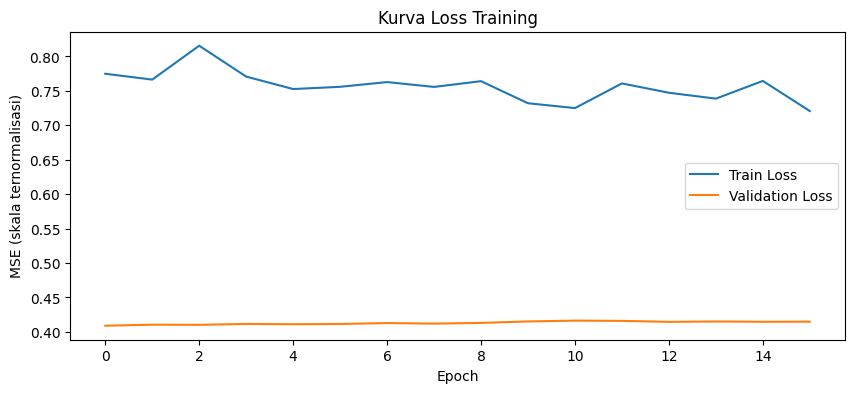

In [34]:
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Kurva Loss Training'); plt.xlabel('Epoch'); plt.ylabel('MSE (skala ternormalisasi)')
plt.legend(); plt.show()

## 9. Evaluasi
Model dibandingkan dengan **baseline persistence** (prediksi besok = nilai hari ini). Karena PM2.5 harian sangat autokorelasi, baseline ini sulit dikalahkan, sehingga menjadi tolok ukur yang jujur.

> **Catatan:** periode test memuat episode kabut asap dengan PM2.5 jauh di atas semua nilai pada data latih (lihat ringkasan periode di bagian 5). Ini pergeseran distribusi yang wajar pada data lingkungan dan perlu disebut dalam pembahasan laporan.

In [35]:
def prediksi_nilai(X_split, pos_split):
    """Prediksi delta -> kembalikan ke skala µg/m³: PM2.5_besok = expm1(log1p(PM2.5_hari_ini) + delta)."""
    delta = target_scaler.inverse_transform(model.predict(X_split, verbose=0)).ravel()
    hari_ini = daily[TARGET].values[pos_split - 1]
    return np.expm1(np.log1p(hari_ini) + delta), hari_ini

def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        'RMSE': float(np.sqrt(mse)),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'MAPE (%)': float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
        'R2': float(r2_score(y_true, y_pred)),
    }

# Baseline naive/persistence: prediksi besok = nilai hari ini
pos_val, pos_te = pos[idx_va], pos[idx_te]
pred_val, base_val = prediksi_nilai(X_val, pos_val)
predictions, base_test = prediksi_nilai(X_test, pos_te)
y_val_actual = daily[TARGET].values[pos_val]
y_actual = daily[TARGET].values[pos_te]

metrics_lstm = evaluate(y_actual, predictions)
metrics_base = evaluate(y_actual, base_test)
metrics_lstm_val = evaluate(y_val_actual, pred_val)
metrics_base_val = evaluate(y_val_actual, base_val)

print(f"Root Mean Squared Error (RMSE) LSTM (test): {metrics_lstm['RMSE']:.2f} µg/m³\n")
print('== Data Validation ==')
display(pd.DataFrame({'LSTM': metrics_lstm_val, 'Baseline (persistence)': metrics_base_val}).round(3))
print('== Data Test ==')
display(pd.DataFrame({'LSTM': metrics_lstm, 'Baseline (persistence)': metrics_base}).round(3))

Root Mean Squared Error (RMSE) LSTM (test): 5.25 µg/m³

== Data Validation ==


,LSTM,Baseline (persistence)
RMSE,1.746,1.892
MAE,1.419,1.525
MAPE (%),6.553,7.065
R2,0.687,0.633


== Data Test ==


,LSTM,Baseline (persistence)
RMSE,5.253,4.726
MAE,3.128,2.873
MAPE (%),7.745,7.682
R2,0.922,0.937


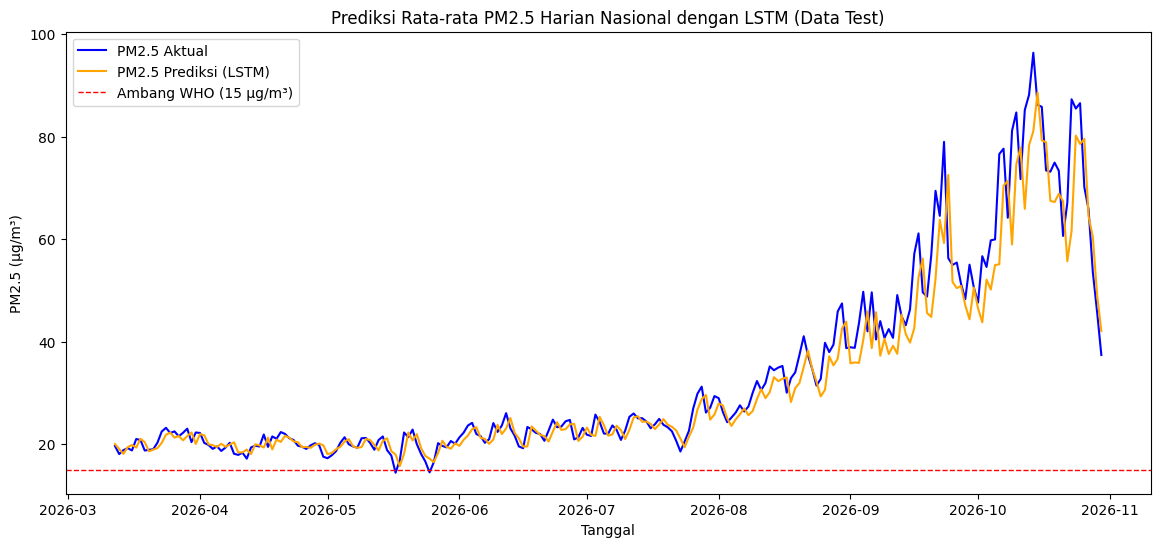

In [36]:
plt.figure(figsize=(14, 6))
plt.plot(dates_test, y_actual, color='blue', label='PM2.5 Aktual')
plt.plot(dates_test, predictions, color='orange', label='PM2.5 Prediksi (LSTM)')
plt.axhline(15, color='red', ls='--', lw=1, label='Ambang WHO (15 µg/m³)')
plt.title('Prediksi Rata-rata PM2.5 Harian Nasional dengan LSTM (Data Test)')
plt.xlabel('Tanggal'); plt.ylabel('PM2.5 (µg/m³)'); plt.legend(); plt.show()

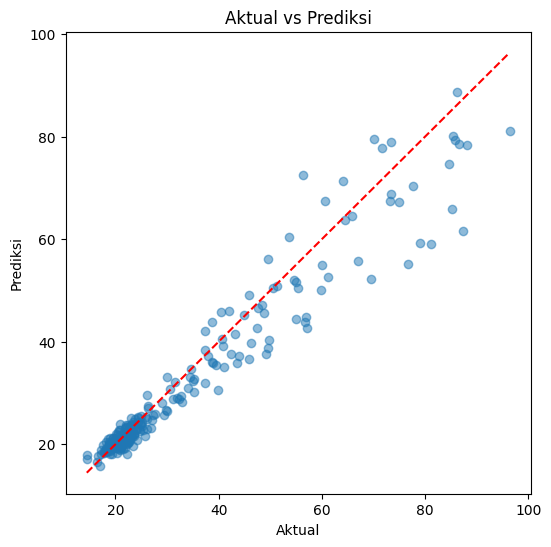

In [38]:
plt.figure(figsize=(6, 6))
plt.scatter(y_actual, predictions, alpha=0.5)
lim = [min(y_actual.min(), predictions.min()), max(y_actual.max(), predictions.max())]
plt.plot(lim, lim, 'r--'); plt.xlabel('Aktual'); plt.ylabel('Prediksi'); plt.title('Aktual vs Prediksi')
plt.show()

## 10. Simpan Model & Artefak ke Folder `model/`
Selain model, scaler dan konfigurasi ikut disimpan karena dibutuhkan saat inferensi di web.

In [39]:
model.save(os.path.join(MODEL_DIR, 'lstm_pm25.keras'))        # model final (bobot terbaik)
joblib.dump(scaler, os.path.join(MODEL_DIR, 'scaler_features.pkl'))
joblib.dump(target_scaler, os.path.join(MODEL_DIR, 'scaler_target.pkl'))

config = {
    'timesteps': TIMESTEPS,
    'features': FEATURES,
    'target': TARGET,
    'target_type': 'delta_log1p',   # model memprediksi log1p(PM2.5_besok) - log1p(PM2.5_hari_ini)
    'raw_cols': RAW_COLS,
    'train_end_date': str(daily.index[train_end - 1].date()),
    'last_data_date': str(daily.index[-1].date()),
    'metrics_val': metrics_lstm_val,
    'metrics_test': metrics_lstm,
    'metrics_baseline_val': metrics_base_val,
    'metrics_baseline_test': metrics_base,
}
with open(os.path.join(MODEL_DIR, 'config.json'), 'w') as f:
    json.dump(config, f, indent=2)

print('Isi folder model/:', os.listdir(MODEL_DIR))

Isi folder model/: ['config.json', 'lstm_pm25.keras', 'lstm_pm25_best.keras', 'scaler_features.pkl', 'scaler_target.pkl']


## 11. Prediksi PM2.5 Esok Hari
Fungsi ini dipakai ulang di web: memuat model dari folder `model/`, mengambil `TIMESTEPS` hari terakhir, lalu memprediksi hari berikutnya. Input berupa data harian nasional (`RAW_COLS`, nilai asli); `buat_fitur()` harus disertakan di sisi web agar preprocessing identik. Kategori mengikuti ambang PM2.5 24 jam **US EPA** (µg/m³) sebagai contoh level peringatan dini.

In [40]:
def kategori_pm25(v):
    if v <= 9.0:   return 'Baik'
    if v <= 35.4:  return 'Sedang'
    if v <= 55.4:  return 'Tidak sehat bagi kelompok sensitif'
    if v <= 125.4: return 'Tidak sehat'
    if v <= 225.4: return 'Sangat tidak sehat'
    return 'Berbahaya'

def prediksi_besok(window_df, model_dir=MODEL_DIR):
    """window_df: DataFrame dengan kolom FEATURES, minimal TIMESTEPS baris terakhir (urut tanggal)."""
    cfg = json.load(open(os.path.join(model_dir, 'config.json')))
    mdl = load_model(os.path.join(model_dir, 'lstm_pm25.keras'))
    sc = joblib.load(os.path.join(model_dir, 'scaler_features.pkl'))
    tsc = joblib.load(os.path.join(model_dir, 'scaler_target.pkl'))

    w_raw = window_df[cfg['raw_cols']].tail(cfg['timesteps'])
    w = buat_fitur(w_raw)
    x = sc.transform(w).reshape(1, cfg['timesteps'], len(cfg['features']))
    delta = float(tsc.inverse_transform(mdl.predict(x, verbose=0))[0, 0])
    nilai = float(np.expm1(np.log1p(w_raw[cfg['target']].iloc[-1]) + delta))
    tanggal = w_raw.index[-1] + pd.Timedelta(days=1)
    return tanggal, nilai

tgl, nilai = prediksi_besok(daily)
print(f'Prediksi rata-rata PM2.5 nasional {tgl.date()}: {nilai:.2f} µg/m³ -> {kategori_pm25(nilai)}')

Prediksi rata-rata PM2.5 nasional 2026-10-31: 34.38 µg/m³ -> Sedang


## 12. Kesimpulan
- Bandingkan **RMSE/MAE/R²** LSTM dengan **baseline persistence** pada tabel evaluasi (validation dan test). Pada data test, performa dipengaruhi pergeseran distribusi akibat episode kabut asap yang tidak ada di data latih.
- Model, scaler, dan `config.json` tersimpan di folder `model/` dan siap dipakai pada implementasi web.
- Pengembangan lanjutan: tuning hyperparameter (`TIMESTEPS`, jumlah unit), tambah fitur cuaca, model per-kota/per-pulau, atau perbandingan dengan GRU/Transformer.